# Hero Multiclass Image Classification

- **Dataset:** Small 3-class actor image dataset (`allu arjun`, `prabhas`, `sharukh`) — 257 training images and 57 validation images.
- **Baseline (Custom CNN):** 3-layer `Conv2D` model trained from scratch for 10 epochs (reaches ~63.16% validation accuracy).
- **Transfer Learning (`DenseNet121`):** ImageNet-pretrained `DenseNet121` trained end-to-end for 7 epochs (95.72% train accuracy, 77.19% validation accuracy; single-image test on `allu.jpeg` still mispredicts `prabhas` due to class imbalance / small dataset).
- **Note:** Despite the filename (`hero_multiclass_with_yolo26.ipynb`), this notebook currently contains only the custom CNN and `DenseNet121` experiments—YOLO26 (`yolo26n-cls.pt` / `yolo26s-cls.pt`) has not been implemented here yet.

In [4]:
import zipfile
zip_ref = zipfile.ZipFile("/content/heros-dataset.zip", 'r')
zip_ref.extractall()
zip_ref.close()

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [6]:
# Apply augmentation only to training data.
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32


In [7]:
# Directory generators for the seven emotion classes.
train_data = train_datagen.flow_from_directory(
    r"/content/heros/train",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_data = val_datagen.flow_from_directory(
    r"/content/heros/test",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Training classes:", train_data.class_indices)
print("Training samples:", train_data.samples)
print("Validation samples:", val_data.samples)

Found 257 images belonging to 3 classes.
Found 57 images belonging to 3 classes.
Training classes: {'allu arjun': 0, 'prabhas': 1, 'sharukh': 2}
Training samples: 257
Validation samples: 57


In [8]:
#making cnn model
from tensorflow.keras.layers import Input

model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(Conv2D(32,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Conv2D(64,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Conv2D(128,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(3,activation='softmax'))

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,177,411 (42.64 MB)

 Trainable params: 11,177,411 (42.64 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [11]:
history = model.fit(train_data,epochs=10,validation_data=val_data)
history

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 43s 5s/step - accuracy: 0.4630 - loss: 1.1405 - val_accuracy: 0.5263 - val_loss: 0.9719
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 35s 4s/step - accuracy: 0.5019 - loss: 0.9880 - val_accuracy: 0.5965 - val_loss: 0.9655
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.5486 - loss: 0.9381 - val_accuracy: 0.5439 - val_loss: 0.9618
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 35s 4s/step - accuracy: 0.4202 - loss: 0.9357 - val_accuracy: 0.3860 - val_loss: 0.9648
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.6031 - loss: 0.8502 - val_accuracy: 0.5965 - val_loss: 1.0505
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 35s 4s/step - accuracy: 0.6459 - loss: 0.8673 - val_accuracy: 0.5789 - val_loss: 0.9618
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 37s 5s/step - accuracy: 0.6732 - loss: 0.8397 - val_accuracy: 0.6491 - val_loss: 0.9813
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 35s 4s/step - accuracy: 0.6654 - loss: 0.7676 - val_accuracy: 0.5439 - val_loss: 0.9648
Epoch 9/

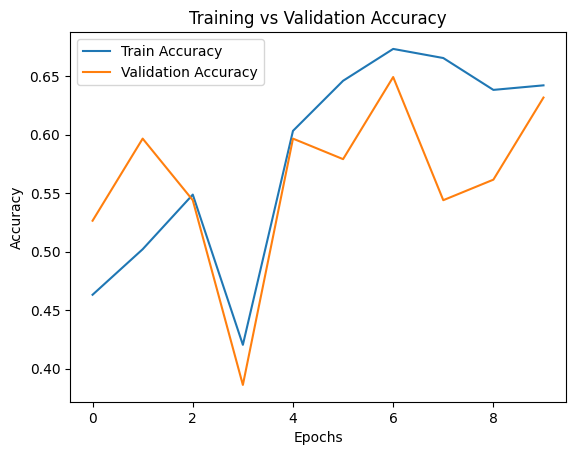

In [12]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training vs Validation Accuracy')
plt.show()

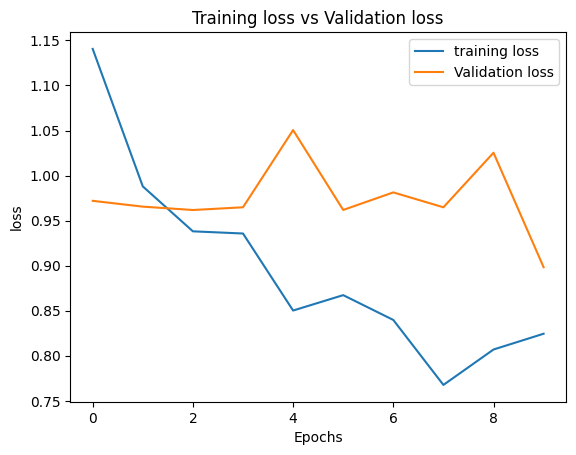

In [13]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.title('Training loss vs Validation loss')
plt.show()

In [14]:
# from tensorflow.keras.preprocessing import image
# import numpy as np

# # 1. Load image
# img_path = r"/content/download (5).jpg"
# img = image.load_img(img_path, target_size=(224, 224))

# # 2. Convert to array
# img_array = image.img_to_array(img)

# # 3. Normalize (same as training)
# img_array = img_array / 255.0

# # 4. Add batch dimension
# img_array = np.expand_dims(img_array, axis=0)

# # 5. Predict
# prediction = model.predict(img_array)

# # 6. Interpret result for multiclass
# # Map indices back to the class names
# class_labels = {v: k for k, v in train_data.class_indices.items()}
# predicted_class_index = np.argmax(prediction[0])
# predicted_class_name = class_labels[predicted_class_index]
# confidence = prediction[0][predicted_class_index] * 100

# print(f"Predicted Class: {predicted_class_name} ({confidence:.2f}% confidence)")

In [15]:
base=tf.keras.applications.DenseNet121(
    include_top=False,
    weights='imagenet',
    input_shape=(224,224,3),
    input_tensor=None,
    pooling='avg',
    classes=3,
    classifier_activation='softmax',
    name="densenet121",
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [16]:
model=Sequential([
    base,
    Flatten(),
    Dense(512,activation='relu'),
    Dropout(0.15),
    Dense(256,activation='relu'),
    Dropout(0.15),
    Dense(3,activation='softmax')
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 1024)           │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,694,403 (29.35 MB)

 Trainable params: 7,610,755 (29.03 MB)

 Non-trainable params: 83,648 (326.75 KB)

In [17]:
from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])
history=model.fit(train_data,validation_data=val_data,epochs=7)

Epoch 1/7
9/9 ━━━━━━━━━━━━━━━━━━━━ 342s 30s/step - accuracy: 0.5370 - loss: 0.9296 - val_accuracy: 0.5263 - val_loss: 0.9232
Epoch 2/7
9/9 ━━━━━━━━━━━━━━━━━━━━ 265s 29s/step - accuracy: 0.7315 - loss: 0.6534 - val_accuracy: 0.6667 - val_loss: 0.8241
Epoch 3/7
9/9 ━━━━━━━━━━━━━━━━━━━━ 261s 29s/step - accuracy: 0.8444 - loss: 0.4944 - val_accuracy: 0.7018 - val_loss: 0.8157
Epoch 4/7
9/9 ━━━━━━━━━━━━━━━━━━━━ 262s 29s/step - accuracy: 0.8327 - loss: 0.4102 - val_accuracy: 0.7018 - val_loss: 0.7086
Epoch 5/7
9/9 ━━━━━━━━━━━━━━━━━━━━ 323s 29s/step - accuracy: 0.8599 - loss: 0.3562 - val_accuracy: 0.7544 - val_loss: 0.5932
Epoch 6/7
9/9 ━━━━━━━━━━━━━━━━━━━━ 259s 29s/step - accuracy: 0.9300 - loss: 0.2528 - val_accuracy: 0.7895 - val_loss: 0.5453
Epoch 7/7
9/9 ━━━━━━━━━━━━━━━━━━━━ 263s 29s/step - accuracy: 0.9572 - loss: 0.1735 - val_accuracy: 0.7719 - val_loss: 0.6274


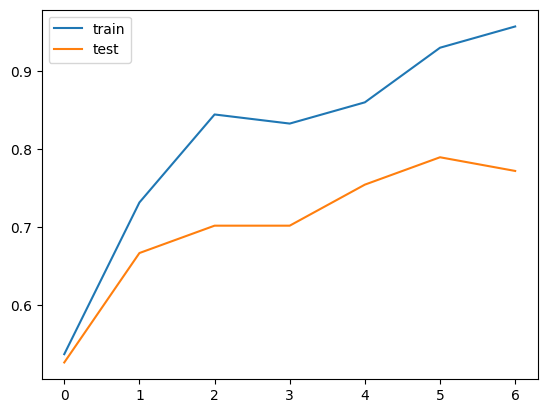

In [18]:
plt.plot(history.history['accuracy'],label='train')
plt.plot(history.history['val_accuracy'],label='test')
plt.legend()

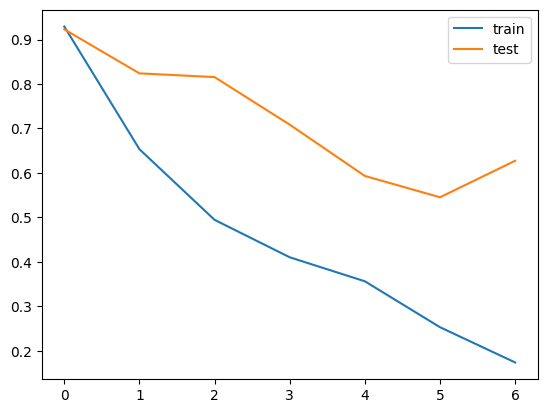

In [19]:
plt.plot(history.history['loss'],label='train')
plt.plot(history.history['val_loss'],label='test')
plt.legend()

In [21]:
from tensorflow.keras.preprocessing import image
import numpy as np

# 1. Load image
img_path = r"/content/allu.jpeg"
img = image.load_img(img_path, target_size=(224, 224))

# 2. Convert to array
img_array = image.img_to_array(img)

# 3. Normalize (same as training)
img_array = img_array / 255.0

# 4. Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# 5. Predict
prediction = model.predict(img_array)

# 6. Interpret result for multiclass
# Map indices back to the class names
class_labels = {v: k for k, v in train_data.class_indices.items()}
predicted_class_index = np.argmax(prediction[0])
predicted_class_name = class_labels[predicted_class_index]
confidence = prediction[0][predicted_class_index] * 100

print(f"Predicted Class: {predicted_class_name} ({confidence:.2f}% confidence)")

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Predicted Class: prabhas (98.90% confidence)
